# 06 – Business Analytics (Task E01–E05)

**CommerceFlow 360** · Người phụ trách: **Quỳnh Kha** · Mục báo cáo: 4.1–4.4

1. `dbt build` toàn bộ (Silver → Gold → 3 Data Mart + mọi test) và xuất `data/exports/*.parquet` cho dashboard (E01–E03, E05).
2. Chạy 10 truy vấn KPI `analytics/sql/analysis_<mart>_<nội dung>.sql` (E04), xuất bảng `reports/tables/Bang_4.x_*.csv`
   và biểu đồ `reports/figures/Hinh_4.x_*.png` cho Chương 4.

Logic dùng chung với `scripts/export_parquet.py` và `scripts/run_e04_analytics.py` (nằm trong `src/reporting/`).

## 1. Chuẩn bị môi trường

In [1]:
# Trên Colab: clone repository và cài thư viện (bỏ qua khi chạy trong repository trên máy cá nhân)
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not Path('/content/CommerceFlow360').exists():
        !git clone -q https://github.com/huyenpiano1711/CommerceFlow360.git /content/CommerceFlow360
    %cd /content/CommerceFlow360
    %pip install -q -r requirements.txt

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'dbt_project' / 'dbt_project.yml').is_file())
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.project import DUCKDB_PATH, FIGURE_DIR, TABLE_DIR
from src.reporting.exports import build_and_export
from src.reporting.kpi_report import REPORTS, export_test_summary, run_report

assert DUCKDB_PATH.is_file(), 'Chưa có commerceflow.duckdb - chạy notebook 02 trước.'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DUCKDB_PATH :', DUCKDB_PATH)

PROJECT_ROOT: D:\CommerceFlow360
DUCKDB_PATH : D:\CommerceFlow360\commerceflow.duckdb


## 2. Build Data Mart và xuất Parquet (E01–E03, E05)

Dừng nếu có model lỗi hoặc test FAIL; các test WARN là bất thường có thật của dữ liệu nguồn đã gắn cờ ở Silver.

In [2]:
quality = build_and_export()

$ dbt build


 test not_null_mart_sales_order_item_id ........................ [RUN]
06:58:59  111 of 113 START test not_null_mart_sales_revenue .............................. [RUN]
06:58:59  108 of 113 START test not_null_mart_sales_is_valid_sale ........................ [RUN]
06:58:59  109 of 113 START test not_null_mart_sales_order_id ............................. [RUN]
06:59:00  108 of 113 PASS not_null_mart_sales_is_valid_sale .............................. [PASS in 0.65s]
06:59:00  111 of 113 PASS not_null_mart_sales_revenue .................................... [PASS in 0.69s]
06:59:00  112 of 113 START test test_mart_reconciliation ................................. [RUN]
06:59:00  113 of 113 START test unique_combination_mart_sales_order_id__order_item_id .... [RUN]
06:59:00  109 of 113 PASS not_null_mart_sales_order_id ................................... [PASS in 1.03s]
06:59:00  110 of 113 PASS not_null_mart_sales_order_item_id .............................. [PASS in 1.11s]
06:59:01  113 of

mart_sales: 112650 dong -> data/exports/mart_sales.parquet


mart_delivery: 100010 dong -> data/exports/mart_delivery.parquet


mart_customer: 96096 dong -> data/exports/mart_customer.parquet
quality_results: 91 test -> data/exports/quality_results.parquet
status
pass    86
warn     5


## 3. Tóm tắt kiểm thử – mục 4.1

In [3]:
export_test_summary()

Bang: Bang_4.1.1_TomTatKiemThu.csv


,status,so_luong
0,pass,86
1,warn,5
2,total,91


## 4. Truy vấn KPI, bảng và biểu đồ (E04)

### 4.1. Phân tích doanh thu (mart_sales) – mục 4.2

Bang: Bang_4.2.1_DoanhThuTheoThang.csv


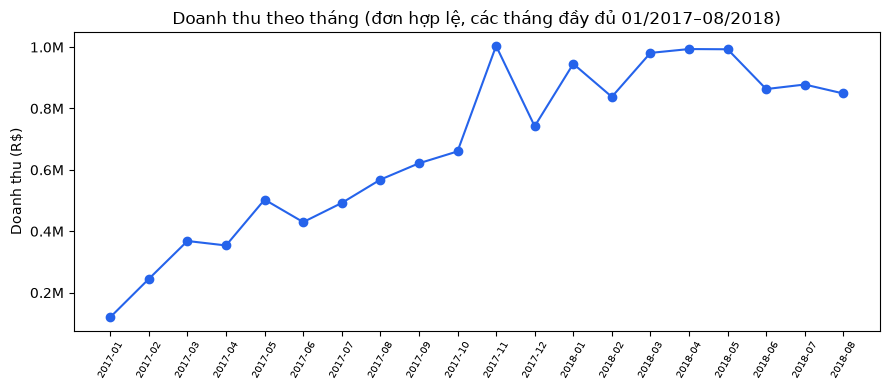

Hinh: Hinh_4.2.1_DoanhThuTheoThang.png


,year,month,month_name,revenue,order_count,avg_order_value
0,2017,1,January,120098.27,787,152.60
1,2017,2,February,244959.35,1718,142.58
2,2017,3,March,368341.32,2617,140.75
3,2017,4,April,353842.98,2377,148.86
4,2017,5,May,503159.19,3640,138.23
5,2017,6,June,429916.61,3205,134.14
6,2017,7,July,492287.30,3946,124.76
7,2017,8,August,568245.79,4272,133.02
8,2017,9,September,621415.91,4227,147.01
9,2017,10,October,660179.62,4547,145.19


In [4]:
run_report('sales_monthly_revenue', show=True)

Bang: Bang_4.2.2_Top10DanhMuc.csv


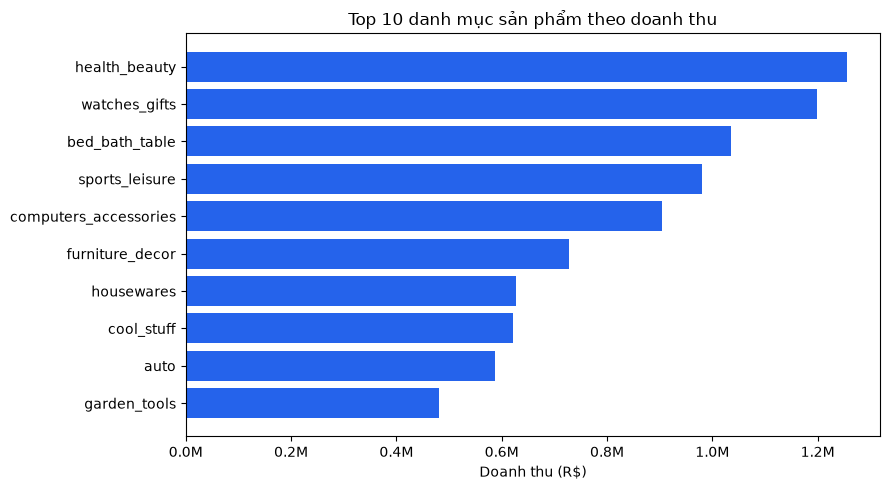

Hinh: Hinh_4.2.2_Top10DanhMuc.png


,product_category,revenue,order_count
0,health_beauty,1255695.13,8800
1,watches_gifts,1198185.21,5604
2,bed_bath_table,1035964.06,9399
3,sports_leisure,979740.92,7673
4,computers_accessories,904322.02,6654
5,furniture_decor,727465.05,6425
6,housewares,626825.80,5847
7,cool_stuff,620770.49,3616
8,auto,586585.73,3872
9,garden_tools,481009.94,3505


In [5]:
run_report('sales_category_revenue', show=True)

Bang: Bang_4.2.3_Top10BangKhachHang.csv


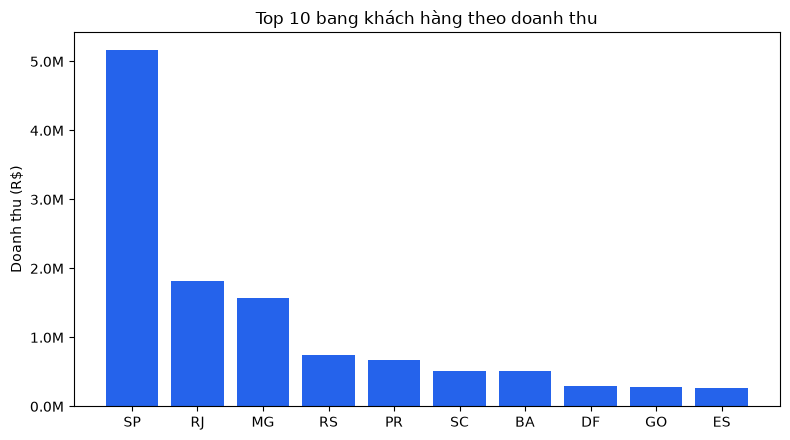

Hinh: Hinh_4.2.3_Top10BangKhachHang.png


,customer_state,revenue,order_count,avg_order_value
0,SP,5163867.22,41125,125.57
1,RJ,1811623.42,12697,142.68
2,MG,1573508.20,11496,136.87
3,RS,742559.78,5415,137.13
4,PR,676883.06,4982,135.87
5,SC,518578.28,3599,144.09
6,BA,507108.83,3344,151.65
7,DF,300886.45,2120,141.93
8,GO,287870.46,1998,144.08
9,ES,273532.13,2018,135.55


In [6]:
run_report('sales_state_revenue', show=True)

In [7]:
run_report('sales_holiday_aov', show=True)

Bang: Bang_4.2.4_AOV_NgayLe_vs_NgayThuong.csv


,is_holiday,revenue,order_count,avg_order_value
0,True,199085.23,1508,132.02
1,False,13295315.51,96691,137.50


### 4.2. Phân tích vận hành giao hàng (mart_delivery) – mục 4.3

Bang: Bang_4.3.1_TyLeGiaoTreTheoBang.csv


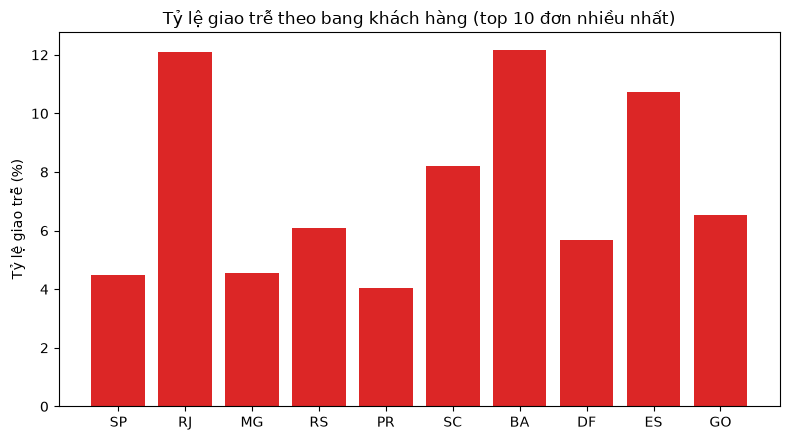

Hinh: Hinh_4.3.1_TyLeGiaoTreTheoBang.png


,customer_state,order_count,late_rate,avg_days_late
0,SP,40494,0.0449,0.37
1,RJ,12350,0.1211,1.64
2,MG,11354,0.0457,0.38
3,RS,5344,0.0608,0.62
4,PR,4923,0.0404,0.34
5,SC,3546,0.0821,0.68
6,BA,3256,0.1216,1.46
7,DF,2080,0.0567,0.42
8,ES,1995,0.1073,1.21
9,GO,1957,0.0654,0.74


In [8]:
run_report('delivery_late_rate_by_state', show=True)

In [9]:
run_report('delivery_late_rate_by_seller', show=True)

Bang: Bang_4.3.2_TopSellerGiaoTre.csv


,seller_id,order_count,late_rate,avg_review_score
0,ede0c03645598cdfc63ca8237acbe73d,43,0.3256,3.57
1,ad781527c93d00d89a11eecd9dcad7c1,38,0.3158,3.34
2,54965bbe3e4f07ae045b90b0b8541f52,73,0.3014,3.14
3,2a1348e9addc1af5aaa619b1a3679d6b,48,0.2708,3.17
4,835f0f7810c76831d6c7d24c7a646d4d,42,0.2619,3.36
5,beadbee30901a7f61d031b6b686095ad,64,0.2344,3.91
6,a49928bcdf77c55c6d6e05e09a9b4ca5,96,0.2188,3.03
7,ef990a83bbea832f36ebe81376335aa8,43,0.2093,3.63
8,712e6ed8aa4aa1fa65dab41fed5737e4,77,0.2078,3.39
9,3fd1e727ba94cfe122d165e176ce7967,35,0.2000,3.94


Bang: Bang_4.3.3_DiemDanhGia_DungHan_vs_Tre.csv


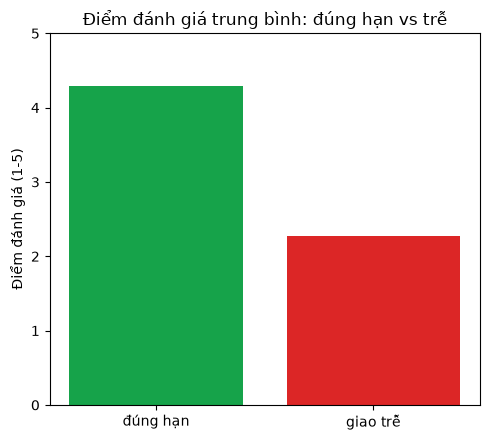

Hinh: Hinh_4.3.2_DiemDanhGia_DungHan_vs_Tre.png


,nhom_giao_hang,order_count,avg_review_score
0,đúng hạn,89443,4.29
1,giao trễ,6381,2.27


In [10]:
run_report('delivery_review_by_ontime', show=True)

### 4.3. Phân tích khách hàng (mart_customer) – mục 4.4

Bang: Bang_4.4.1_TyLeMuaLai.csv


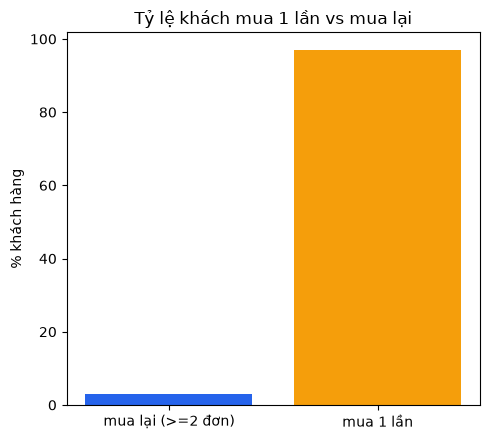

Hinh: Hinh_4.4.1_TyLeMuaLai.png


,nhom_khach_hang,customer_count,pct_customers,avg_total_spend
0,mua lại (>=2 đơn),2888,3.04,308.36
1,mua 1 lần,92102,96.96,161.22


In [11]:
run_report('customer_repeat_rate', show=True)

Bang: Bang_4.4.2_PhanKhucChiTieu.csv


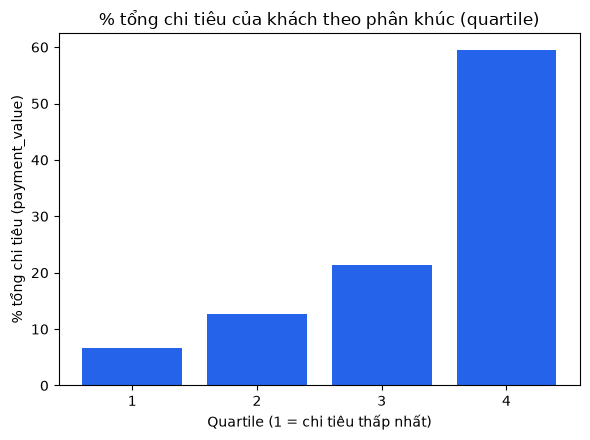

Hinh: Hinh_4.4.2_PhanKhucChiTieu.png


,spend_quartile,customer_count,min_spend,max_spend,total_spend_segment,pct_total_spend
0,1,23748,9.59,63.10,1036556.95,6.59
1,2,23747,63.10,107.90,1987313.44,12.63
2,3,23747,107.92,182.94,3354705.92,21.31
3,4,23747,182.95,13664.08,9360560.70,59.47


In [12]:
run_report('customer_spend_segments', show=True)

Bang: Bang_4.4.3_PhanBoRecency.csv


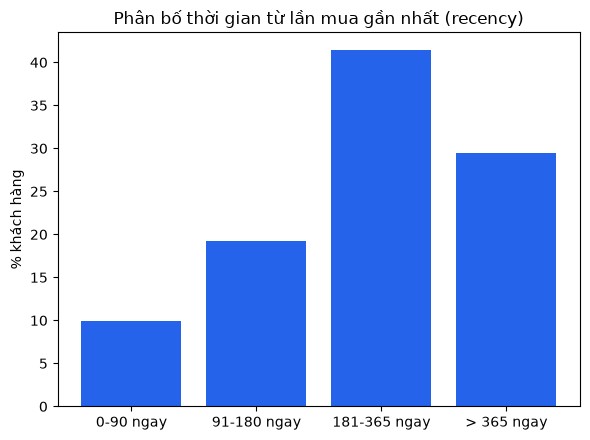

Hinh: Hinh_4.4.3_PhanBoRecency.png


,nhom_recency,customer_count,pct_customers
0,0-90 ngay,9463,9.96
1,91-180 ngay,18234,19.20
2,181-365 ngay,39348,41.42
3,> 365 ngay,27945,29.42


In [13]:
run_report('customer_recency', show=True)

## 5. Kiểm tra đầu ra

In [14]:
expected_tables = ['Bang_4.1.1_TomTatKiemThu.csv'] + [r.table for r in REPORTS.values()]
expected_figures = [r.figure for r in REPORTS.values() if r.figure]
checks = {
    f'đủ {len(expected_tables)} bảng Chương 4': all((TABLE_DIR / f).is_file() for f in expected_tables),
    f'đủ {len(expected_figures)} hình Chương 4': all((FIGURE_DIR / f).is_file() for f in expected_figures),
}
print(checks)
assert all(checks.values()), 'Thiếu bảng/hình - xem lại các cell phía trên.'

{'đủ 11 bảng Chương 4': True, 'đủ 8 hình Chương 4': True}
